
<h1>Machine Learning</h1>
<h1>Assignment 2 — AIML ZG565 </h1>
<hr style="border:2px solid gray;">

M. Tech. in Artificial Intelligence & Machine Learning

Student Name: Sithara N T

BITS ID: 2026AJ05271

Semester: 1st (2026-27)

OBJECTIVE:  Machine Learning Classification models and Evaluation metrics    
Implement the following classification models using the dataset chosen above. All
the 5 ML models (Logistic Regression, Decision Tree Classifier, K-Nearest Neighbor Classifier, Naive Bayes Classifier - Gaussian or Multinomial, Support Vector Machine) have to be implemented on the same dataset.

For each of the models above, calculate the following evaluation metrics: Accuracy, AUC Score, Precision, Recall, F1 Score, Matthews Correlation Coefficient (MCC Score)

PROJECT: 
E-Commerce Customer Segmentation Using Machine Learning Classification Algorithms
----------------------------------------------------------

Problem statement: 
Develop a machine learning multiclass classification system using e-commerce sales data to predict the customer segment to which a customer belongs based on their demographic characteristics, purchasing behaviour, order history, spending patterns, product preferences, discount usage, delivery experience and customer ratings.

Target variable: customer_segment

Classification type: Multiclass classification

Target classes:
1. Consumer
2. Premium
3. VIP
4. Business

Algorithms:
- Logistic Regression
- Decision Tree Classifier
- K-Nearest Neighbor Classifier
- Gaussian Naive Bayes
- Support Vector Machine


In [1]:
# ============================================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    matthews_corrcoef,
    roc_auc_score
)

# Save models
import joblib

# ============================================================
# 2. LOAD DATASET
# ============================================================

file_path = "ecommerce_sales_customer_analytics_150k.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

print("Original Dataset Shape:", df.shape)

print("\nFirst Five Records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nNumber of Unique Customers:", df["customer_id"].nunique())

Dataset loaded successfully!
Original Dataset Shape: (138116, 46)

First Five Records:


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  object 
 1   order_date                138116 non-null  object 
 2   order_time                138116 non-null  object 
 3   order_status              138116 non-null  object 
 4   sales_channel             138116 non-null  object 
 5   customer_id               138116 non-null  object 
 6   customer_name             138116 non-null  object 
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  object 
 9   customer_segment          138116 non-null  object 
 10  customer_type             138116 non-null  object 
 11  customer_city             138116 non-null  object 
 12  customer_state            138116 non-null  object 
 13  customer_country      


MISSING VALUES
return_reason               128654
return_status               128654
coupon_code                 110502
campaign_name                83233
customer_review              24557
customer_rating              24557
estimated_delivery_days      24557
delivery_days                24557
review_sentiment             24557
order_id                         0
order_time                       0
order_status                     0
sales_channel                    0
order_date                       0
customer_country                 0
customer_state                   0
customer_city                    0
customer_type                    0
customer_segment                 0
gender                           0
customer_age                     0
customer_name                    0
customer_id                      0
shipping_method                  0
warehouse                        0
payment_status                   0
customer_postal_code             0
payment_method                   0
curr

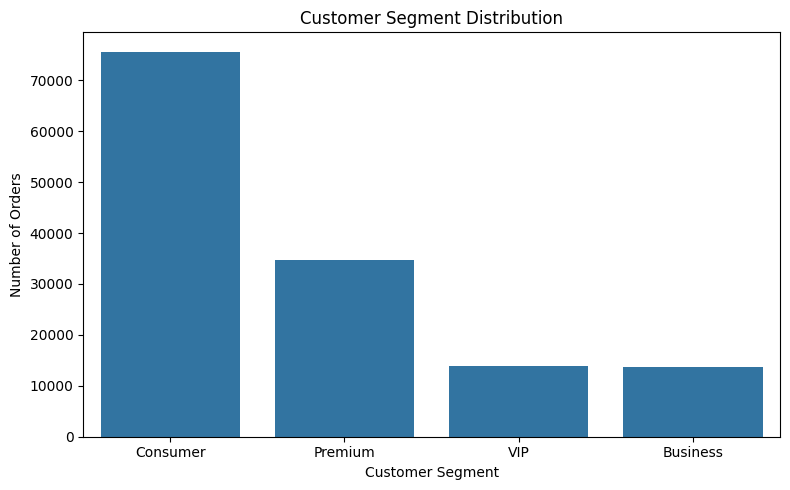

In [2]:
#============================================================
# 3. INITIAL DATA EXPLORATION
# ============================================================

print("\nMISSING VALUES")
print(df.isnull().sum().sort_values(ascending=False))

print("\nDUPLICATE RECORDS:", df.duplicated().sum())

print("\nCUSTOMER SEGMENT DISTRIBUTION")
print(df["customer_segment"].value_counts())

print("\nCUSTOMER TYPE DISTRIBUTION")
print(df["customer_type"].value_counts())

# Visualize customer segments
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="customer_segment",
    order=df["customer_segment"].value_counts().index
)

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [3]:
# ============================================================
# 4. DATA CLEANING
# ============================================================

data = df.copy()

# Remove duplicate records
data = data.drop_duplicates()

# Remove records without customer ID or target
data = data.dropna(
    subset=["customer_id", "customer_segment"]
)

# Check target consistency for every customer
segment_counts = (
    data.groupby("customer_id")["customer_segment"]
    .nunique()
)

print(
    "Customers with inconsistent segment labels:",
    (segment_counts > 1).sum()
)

# We expect one consistent segment per customer.
assert (segment_counts <= 1).all(), (
    "Some customers have multiple customer_segment labels. "
    "Investigate these records before aggregation."
)

# ============================================================
# 5. DATE AND TIME FEATURE ENGINEERING
# ============================================================

data["order_date"] = pd.to_datetime(
    data["order_date"],
    errors="coerce"
)

# Extract date-related attributes
data["order_year"] = data["order_date"].dt.year
data["order_month"] = data["order_date"].dt.month
data["order_day"] = data["order_date"].dt.day
data["order_weekday"] = data["order_date"].dt.dayofweek

# Extract order hour
data["order_hour"] = pd.to_datetime(
    data["order_time"],
    format="%H:%M:%S",
    errors="coerce"
).dt.hour

# Return status:
# In this dataset, missing return_status means no recorded return.
# We treat it as Not Returned for this retrospective experiment.

data["return_status"] = data["return_status"].fillna(
    "Not Returned"
)

data["is_returned_order"] = (
    data["return_status"].str.lower() == "returned"
).astype(int)

# Delivery indicators
data["is_delayed_order"] = (
    data["delivery_status"].str.lower() == "delayed"
).astype(int)

data["is_cancelled_order"] = (
    data["order_status"].str.lower() == "cancelled"
).astype(int)

print("Data cleaning and date engineering completed.")

Customers with inconsistent segment labels: 0
Data cleaning and date engineering completed.


In [4]:
# ============================================================
# 6. CUSTOMER-LEVEL AGGREGATION
# ============================================================

# Group all orders by customer ID
grouped = data.groupby("customer_id", sort=False)

# Create customer-level dataframe
customer_data = pd.DataFrame(index=grouped.size().index)

# ------------------------------------------------------------
# A. CUSTOMER DEMOGRAPHICS
# ------------------------------------------------------------

static_features = [
    "customer_age",
    "gender",
    "customer_state",
    "customer_country",
    "region"
]

for col in static_features:

    if col in data.columns:

        customer_data[col] = grouped[col].first()


# ------------------------------------------------------------
# B. PURCHASE FREQUENCY
# ------------------------------------------------------------

customer_data["order_count"] = grouped.size()

customer_data["unique_order_statuses"] = (
    grouped["order_status"].nunique()
)


# ------------------------------------------------------------
# C. NUMERICAL TRANSACTION AGGREGATION
# ------------------------------------------------------------

numeric_aggregate_features = [
    "quantity",
    "gross_sales",
    "discount_amount",
    "tax_amount",
    "shipping_cost",
    "net_sales",
    "product_cost",
    "profit",
    "profit_margin_percentage",
    "delivery_days",
    "estimated_delivery_days",
    "customer_rating",
    "loyalty_points_earned",
    "loyalty_points_redeemed",
    "order_hour",
    "order_month",
    "order_weekday"
]

for col in numeric_aggregate_features:

    if col in data.columns:

        customer_data[col + "_sum"] = grouped[col].sum()

        customer_data[col + "_mean"] = grouped[col].mean()

        customer_data[col + "_std"] = grouped[col].std()

        customer_data[col + "_min"] = grouped[col].min()

        customer_data[col + "_max"] = grouped[col].max()


# ------------------------------------------------------------
# D. CUSTOMER BEHAVIOUR AND DELIVERY EXPERIENCE
# ------------------------------------------------------------

customer_data["return_count"] = (
    grouped["is_returned_order"].sum()
)

customer_data["return_rate"] = (
    grouped["is_returned_order"].mean()
)

customer_data["delayed_order_count"] = (
    grouped["is_delayed_order"].sum()
)

customer_data["delayed_order_rate"] = (
    grouped["is_delayed_order"].mean()
)

customer_data["cancelled_order_count"] = (
    grouped["is_cancelled_order"].sum()
)

customer_data["cancelled_order_rate"] = (
    grouped["is_cancelled_order"].mean()
)


# ------------------------------------------------------------
# E. DATE-BASED CUSTOMER FEATURES
# ------------------------------------------------------------

customer_data["first_order_date"] = (
    grouped["order_date"].min()
)

customer_data["last_order_date"] = (
    grouped["order_date"].max()
)

reference_date = data["order_date"].max()

customer_data["customer_tenure_days"] = (
    customer_data["last_order_date"]
    - customer_data["first_order_date"]
).dt.days

customer_data["recency_days"] = (
    reference_date - customer_data["last_order_date"]
).dt.days

# Remove raw date columns after calculating date differences
customer_data = customer_data.drop(
    columns=["first_order_date", "last_order_date"]
)


# ------------------------------------------------------------
# F. CATEGORICAL PURCHASE PREFERENCES
# ------------------------------------------------------------

categorical_aggregate_features = [
    "sales_channel",
    "payment_method",
    "payment_status",
    "currency",
    "shipping_method",
    "warehouse",
    "marketing_channel",
    "delivery_status",
    "return_status",
    "review_sentiment"
]


def get_mode(series):

    mode_values = series.mode(dropna=True)

    if len(mode_values) > 0:
        return mode_values.iloc[0]

    return np.nan


for col in categorical_aggregate_features:

    if col in data.columns:

        # Most frequently used category
        customer_data[col + "_mode"] = (
            grouped[col].agg(get_mode)
        )

        # Number of distinct categories used
        customer_data[col + "_nunique"] = (
            grouped[col].nunique()
        )


# ------------------------------------------------------------
# G. CREATE TARGET VARIABLE
# ------------------------------------------------------------

customer_data["customer_segment"] = (
    grouped["customer_segment"].first()
)


# ============================================================
# 7. FINAL CUSTOMER-LEVEL DATASET
# ============================================================

customer_data = customer_data.reset_index()

print("\nCUSTOMER-LEVEL DATASET CREATED")

print("Original Order-Level Shape:", data.shape)

print("Aggregated Customer-Level Shape:", customer_data.shape)

print("\nFirst Five Customer Records:")

display(customer_data.head())

print("\nCustomer Segment Distribution:")

print(customer_data["customer_segment"].value_counts())


CUSTOMER-LEVEL DATASET CREATED
Original Order-Level Shape: (138116, 54)
Aggregated Customer-Level Shape: (24911, 122)

First Five Customer Records:


,customer_id,customer_age,gender,customer_state,customer_country,region,order_count,unique_order_statuses,quantity_sum,quantity_mean,...,warehouse_nunique,marketing_channel_mode,marketing_channel_nunique,delivery_status_mode,delivery_status_nunique,return_status_mode,return_status_nunique,review_sentiment_mode,review_sentiment_nunique,customer_segment
0,CUST-003102,55,Male,Texas,USA,South,9,2,47,5.222222,...,9,Email Marketing,5,On Time,3,Not Returned,1,Positive,2,Consumer
1,CUST-003124,26,Male,Baden-Württemberg,Germany,South,10,3,46,4.600000,...,9,Facebook Ads,6,On Time,2,Not Returned,2,Positive,2,Premium
2,CUST-012496,69,Female,New York,USA,East,5,2,24,4.800000,...,5,Direct,5,On Time,3,Not Returned,1,Positive,2,Premium
3,CUST-023928,65,Male,North Carolina,USA,South,6,3,31,5.166667,...,6,Email Marketing,6,On Time,2,Not Returned,2,Positive,2,Consumer
4,CUST-012730,34,Female,Gujarat,India,West,7,2,40,5.714286,...,6,Organic Search,6,On Time,3,Not Returned,1,Positive,2,Consumer



Customer Segment Distribution:
customer_segment
Consumer    13585
Premium      6275
VIP          2536
Business     2515
Name: count, dtype: int64


In [5]:
# ============================================================
# 8. FEATURE SELECTION
# ============================================================

TARGET = "customer_segment"

# Features to exclude
drop_columns = [
    "customer_id",
    "customer_segment"
]

# Target
y = customer_data[TARGET].copy()

# Input features
X = customer_data.drop(
    columns=drop_columns
)

# Remove any non-feature columns if present
X = X.drop(
    columns=[
        col for col in [
            "customer_name",
            "customer_lifetime_value",
            "customer_order_count",
            "customer_postal_code"
        ]
        if col in X.columns
    ],
    errors="ignore"
)

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Input Dataset Shape:", X.shape)

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTarget Classes:")
print(y.value_counts())

Input Dataset Shape: (24911, 120)

Numerical Features:
['customer_age', 'order_count', 'unique_order_statuses', 'quantity_sum', 'quantity_mean', 'quantity_std', 'quantity_min', 'quantity_max', 'gross_sales_sum', 'gross_sales_mean', 'gross_sales_std', 'gross_sales_min', 'gross_sales_max', 'discount_amount_sum', 'discount_amount_mean', 'discount_amount_std', 'discount_amount_min', 'discount_amount_max', 'tax_amount_sum', 'tax_amount_mean', 'tax_amount_std', 'tax_amount_min', 'tax_amount_max', 'shipping_cost_sum', 'shipping_cost_mean', 'shipping_cost_std', 'shipping_cost_min', 'shipping_cost_max', 'net_sales_sum', 'net_sales_mean', 'net_sales_std', 'net_sales_min', 'net_sales_max', 'product_cost_sum', 'product_cost_mean', 'product_cost_std', 'product_cost_min', 'product_cost_max', 'profit_sum', 'profit_mean', 'profit_std', 'profit_min', 'profit_max', 'profit_margin_percentage_sum', 'profit_margin_percentage_mean', 'profit_margin_percentage_std', 'profit_margin_percentage_min', 'profit_mar

In [6]:
# ============================================================
# 9. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)

print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features: (19928, 120)
Testing Features: (4983, 120)

Training Target Distribution:
customer_segment
Consumer    10867
Premium      5020
VIP          2029
Business     2012
Name: count, dtype: int64

Testing Target Distribution:
customer_segment
Consumer    2718
Premium     1255
VIP          507
Business     503
Name: count, dtype: int64


In [7]:
# ============================================================
# 10. PREPROCESSING PIPELINES
# ============================================================

def create_preprocessor(dense=False):

    # Numerical preprocessing
    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),

        ("scaler", StandardScaler(
            with_mean=dense
        ))
    ])

    # Categorical preprocessing
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="most_frequent"
        )),

        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=10,
            sparse_output=not dense
        ))
    ])

    # Combine pipelines
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numerical",
                numerical_pipeline,
                numeric_features
            ),
            (
                "categorical",
                categorical_pipeline,
                categorical_features
            )
        ],
        sparse_threshold=0 if dense else 1.0
    )

    return preprocessor


# Create preprocessing configurations
preprocessor_sparse = create_preprocessor(dense=False)

preprocessor_dense = create_preprocessor(dense=True)

print("Preprocessing pipelines created successfully!")

Preprocessing pipelines created successfully!


In [8]:
# ============================================================
# 11. INITIALIZE FIVE CLASSIFICATION MODELS
# ============================================================

models = {

    # 1. LOGISTIC REGRESSION
    "Logistic Regression": Pipeline([
        ("preprocessor", create_preprocessor(dense=False)),

        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    # 2. DECISION TREE CLASSIFIER
    "Decision Tree": Pipeline([
        ("preprocessor", create_preprocessor(dense=False)),

        ("classifier", DecisionTreeClassifier(
            max_depth=15,
            min_samples_split=10,
            min_samples_leaf=5,
            random_state=42
        ))
    ]),

    # 3. K-NEAREST NEIGHBOR
    "KNN": Pipeline([
        ("preprocessor", create_preprocessor(dense=False)),

        ("classifier", KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            n_jobs=-1
        ))
    ]),

    # 4. GAUSSIAN NAIVE BAYES
    "Gaussian Naive Bayes": Pipeline([
        ("preprocessor", create_preprocessor(dense=True)),

        ("classifier", GaussianNB(
            var_smoothing=1e-9
        ))
    ]),

    # 5. SUPPORT VECTOR MACHINE
    "Support Vector Machine": Pipeline([
        ("preprocessor", create_preprocessor(dense=False)),

        ("classifier", LinearSVC(
            C=1.0,
            class_weight="balanced",
            max_iter=20000,
            random_state=42
        ))
    ])
}

print("Five classification models initialized successfully!")

for name in models:
    print(name)

Five classification models initialized successfully!
Logistic Regression
Decision Tree
KNN
Gaussian Naive Bayes
Support Vector Machine


In [9]:
# ============================================================
# 12. MODEL TRAINING AND PREDICTION
# ============================================================

results = []

trained_models = {}

predictions = {}

for model_name, model in models.items():

    print("\n" + "=" * 70)
    print("TRAINING:", model_name)
    print("=" * 70)

    # --------------------------------------------------------
    # TRAIN MODEL
    # --------------------------------------------------------

    model.fit(X_train, y_train)

    # Predict test dataset
    y_pred = model.predict(X_test)

    # Store trained model and predictions
    trained_models[model_name] = model
    predictions[model_name] = y_pred

    # --------------------------------------------------------
    # CLASSIFICATION METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    f1_weighted = f1_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    f1_macro = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_test, y_pred
    )

    # Matthews Correlation Coefficient
    mathews = matthews_corrcoef(y_test, y_pred)

    # --------------------------------------------------------
    # MULTICLASS ROC-AUC SCORE (ONE-VS-REST)
    # --------------------------------------------------------

    try:

        classes = model.classes_

        if hasattr(model, "predict_proba"):

            # Probability-based models
            y_score = model.predict_proba(X_test)

            auc = roc_auc_score(
                y_test,
                y_score,
                labels=classes,
                multi_class="ovr",
                average="weighted"
            )

        elif hasattr(model, "decision_function"):

            # LinearSVC: use decision scores
            y_score = np.asarray(
                model.decision_function(X_test)
            )

            print("Decision score shape:", y_score.shape)

            auc_values = []
            class_weights = []

            # Calculate AUC separately for each class
            for i, cls in enumerate(classes):

                y_binary = (
                    np.asarray(y_test) == cls
                ).astype(int)

                # Both positive and negative samples required
                if len(np.unique(y_binary)) < 2:

                    print(
                        f"Skipping AUC for {cls}: "
                        "only one label present"
                    )
                    continue

                class_auc = roc_auc_score(
                    y_binary,
                    y_score[:, i]
                )

                auc_values.append(class_auc)

                class_weights.append(
                    np.sum(y_binary)
                )

                print(
                    f"{cls} AUC: {class_auc:.4f}"
                )

            # Weighted average of class-wise AUC
            if len(auc_values) > 0:

                auc = np.average(
                    auc_values,
                    weights=class_weights
                )

            else:

                auc = np.nan

        else:

            auc = np.nan

    except Exception as e:

        print(
            f"AUC calculation failed for "
            f"{model_name}: {repr(e)}"
        )

        auc = np.nan

    # --------------------------------------------------------
    # STORE RESULTS
    # --------------------------------------------------------

    results.append({

        "Model": model_name,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1 Weighted": f1_weighted,

        "F1 Macro": f1_macro,

        "Balanced Accuracy": balanced_acc,

        "MCC": mathews,

        "AUC": auc

    })

    # --------------------------------------------------------
    # PRINT CLASSIFICATION REPORT
    # --------------------------------------------------------

    print("\nClassification Report:")

    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Weighted:", round(f1_weighted, 4))
    print("F1 Macro:", round(f1_macro, 4))
    print("Balanced Accuracy:", round(balanced_acc, 4))
    print("MCC:", round(mathews, 4))

    if not np.isnan(auc):
        print("ROC-AUC:", round(auc, 4))
    else:
        print("ROC-AUC: Not available")


print("\nALL FIVE MODELS TRAINED SUCCESSFULLY!")


TRAINING: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

    Business       0.15      0.40      0.22       503
    Consumer       0.77      0.46      0.58      2718
     Premium       0.54      0.44      0.49      1255
         VIP       0.25      0.48      0.33       507

    accuracy                           0.45      4983
   macro avg       0.43      0.45      0.40      4983
weighted avg       0.60      0.45      0.49      4983

Accuracy: 0.4529
Precision: 0.5979
Recall: 0.4529
F1 Weighted: 0.4936
F1 Macro: 0.4027
Balanced Accuracy: 0.4461
MCC: 0.2596
ROC-AUC: 0.8085

TRAINING: Decision Tree

Classification Report:
              precision    recall  f1-score   support

    Business       0.16      0.11      0.13       503
    Consumer       0.73      0.83      0.78      2718
     Premium       0.56      0.52      0.54      1255
         VIP       0.23      0.18      0.20       507

    accuracy                           0.61     

In [10]:
# ============================================================
# 13. MODEL PERFORMANCE COMPARISON
# ============================================================

results_df = pd.DataFrame(results)

# Sort according to Macro F1-score
results_df = results_df.sort_values(
    by="F1 Macro",
    ascending=False
).reset_index(drop=True)

print("\nFINAL MODEL COMPARISON")
print("=" * 90)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Weighted": "{:.4f}",
        "F1 Macro": "{:.4f}",
        "Balanced Accuracy": "{:.4f}",
        "MCC": "{:.4f}",
        "AUC": "{:.4f}"
    })
)

# Identify best model
best_model_name = results_df.iloc[0]["Model"]

print("\nBEST PERFORMING MODEL:", best_model_name)

print(
    "Best Macro F1 Score:",
    round(results_df.iloc[0]["F1 Macro"], 4)
)


FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Weighted,F1 Macro,Balanced Accuracy,MCC,AUC
0,Support Vector Machine,0.6623,0.5831,0.6623,0.6189,0.4174,0.4375,0.4213,0.8083
1,Decision Tree,0.6129,0.5785,0.6129,0.5927,0.4111,0.4083,0.3434,0.7079
2,Logistic Regression,0.4529,0.5979,0.4529,0.4936,0.4027,0.4461,0.2596,0.8085
3,Gaussian Naive Bayes,0.4337,0.5034,0.4337,0.4586,0.3413,0.3596,0.1643,0.6551
4,KNN,0.5410,0.4748,0.5410,0.4953,0.3104,0.3160,0.1734,0.6344



BEST PERFORMING MODEL: Support Vector Machine
Best Macro F1 Score: 0.4174


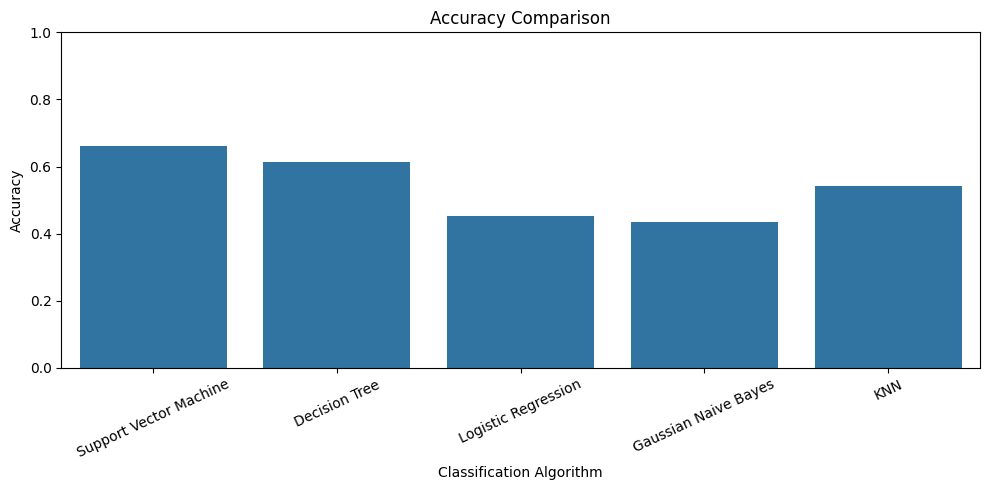

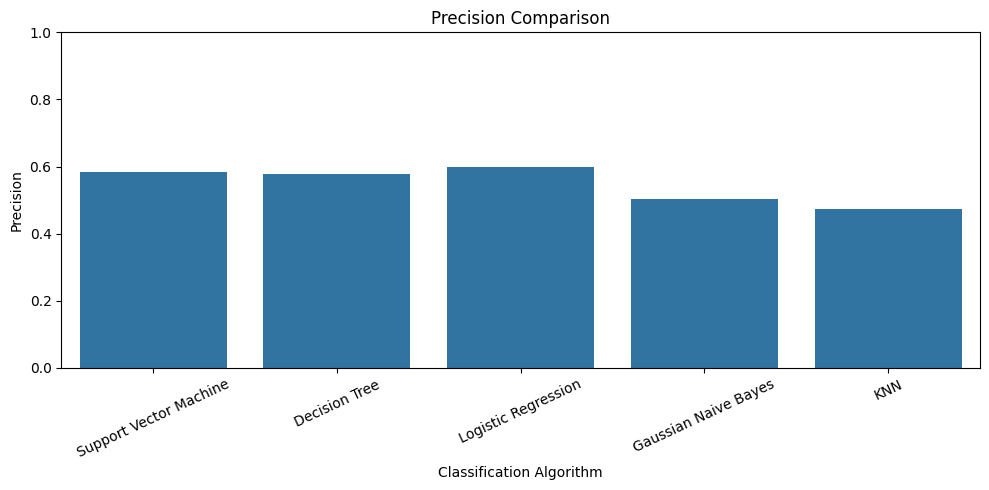

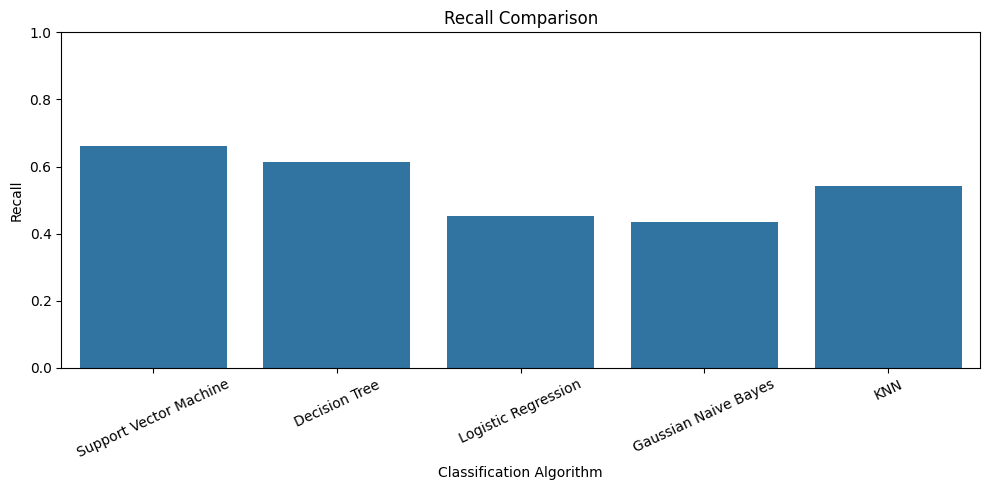

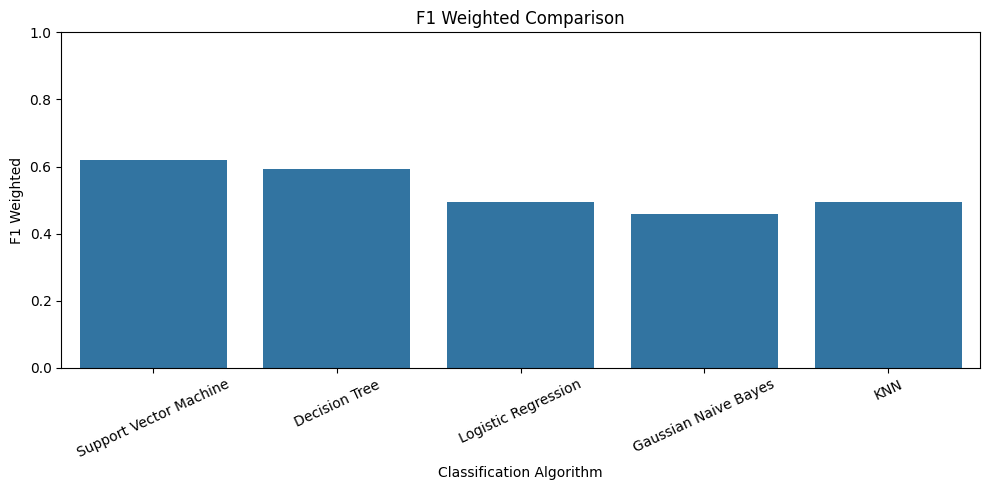

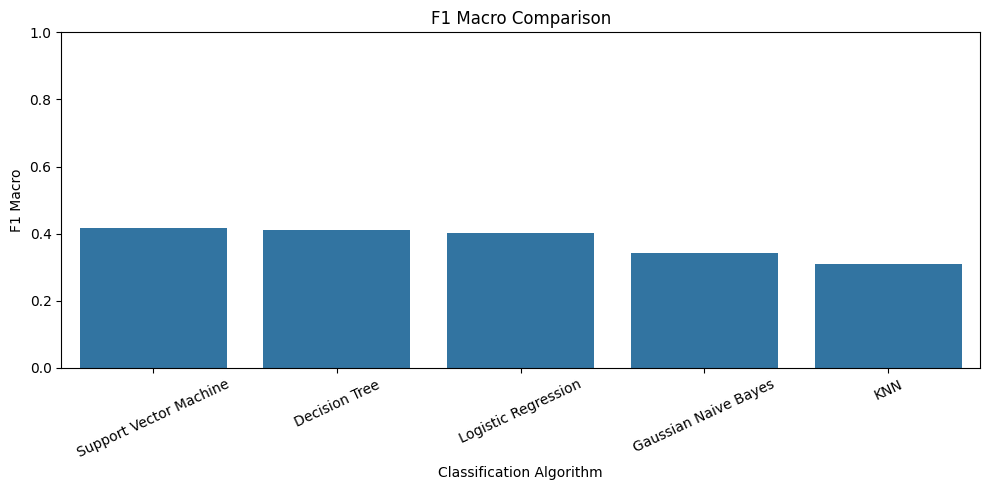

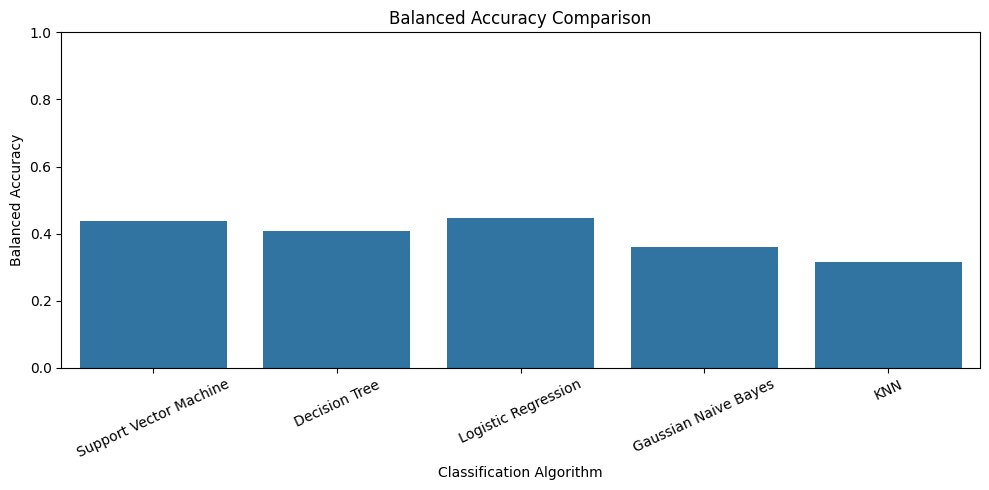

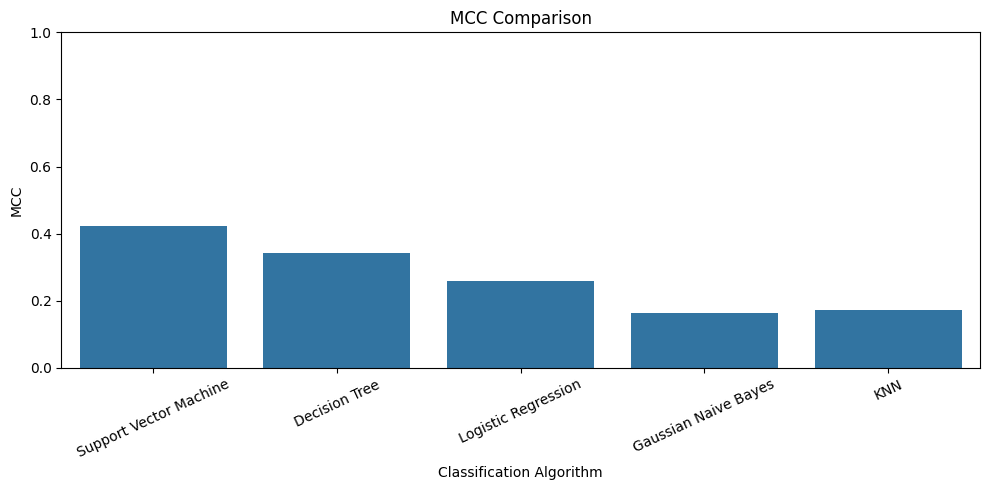

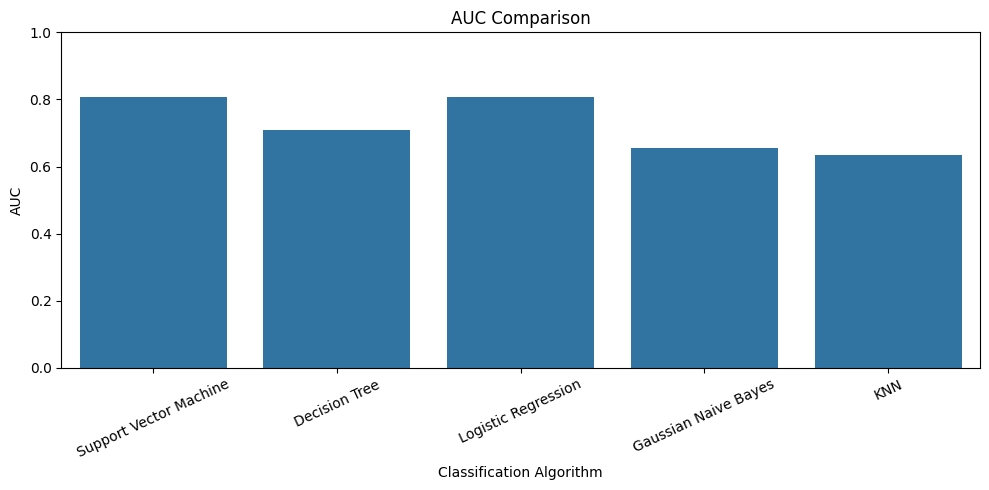

In [11]:
# ============================================================
# 14. PERFORMANCE COMPARISON CHARTS
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Weighted",
    "F1 Macro",
    "Balanced Accuracy",
    "MCC",
    "AUC"
]

for metric in metrics:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(metric + " Comparison")

    plt.xlabel("Classification Algorithm")

    plt.ylabel(metric)

    plt.xticks(rotation=25)

    plt.ylim(0, 1)

    plt.tight_layout()

    plt.show()

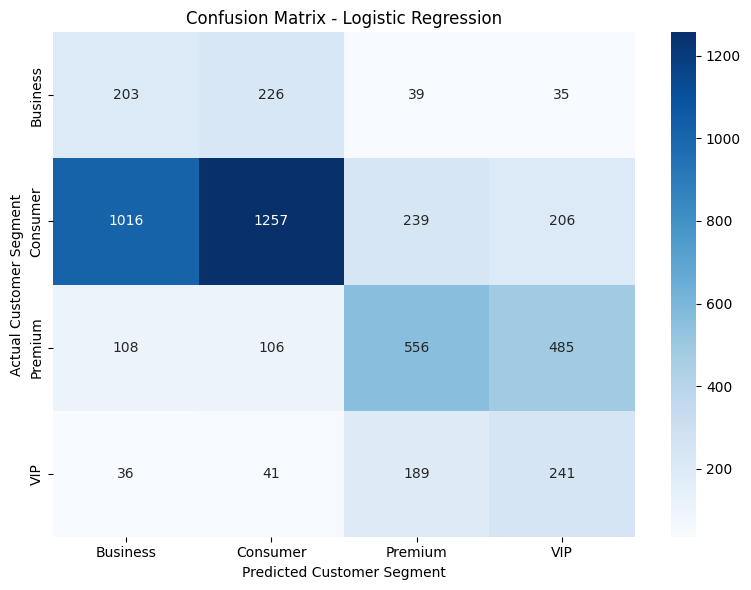

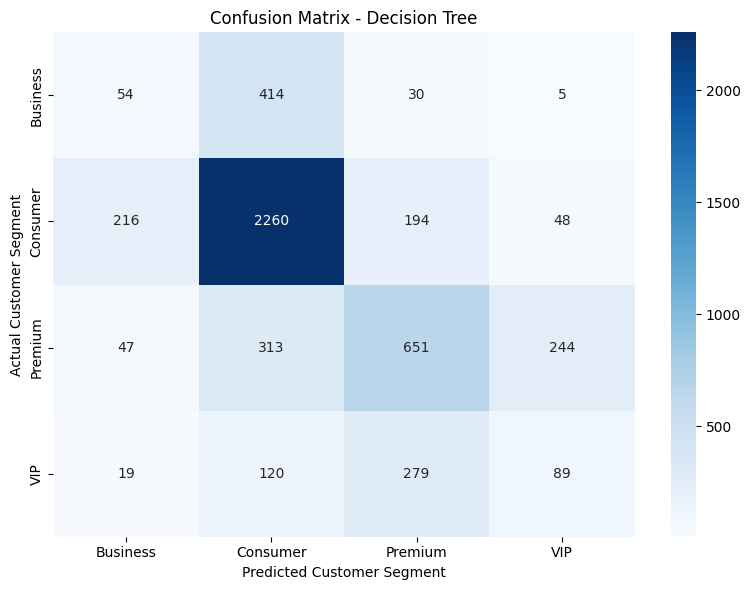

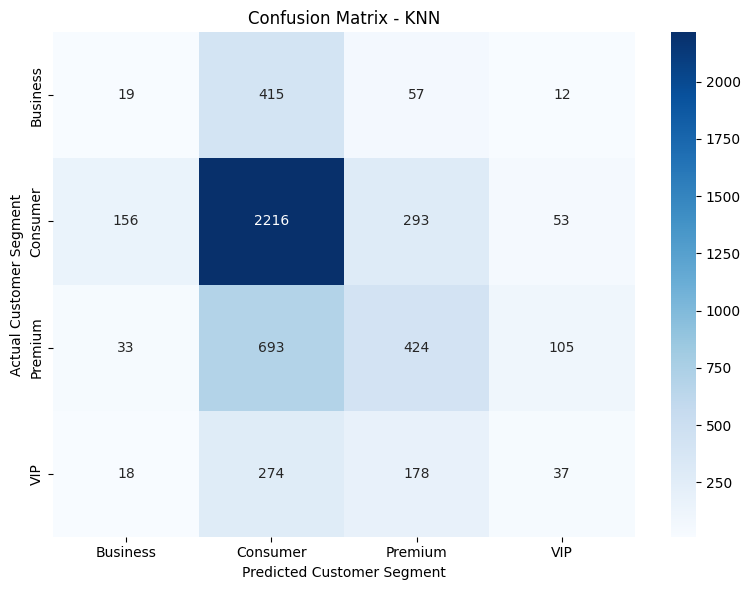

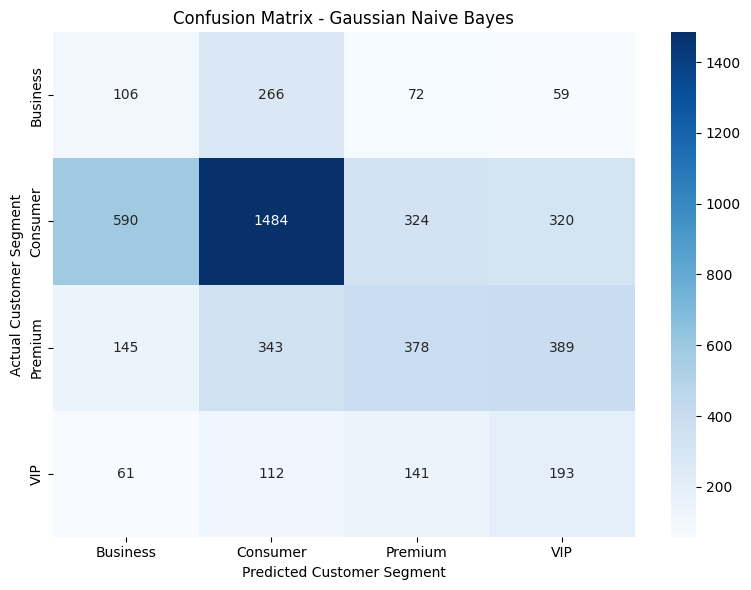

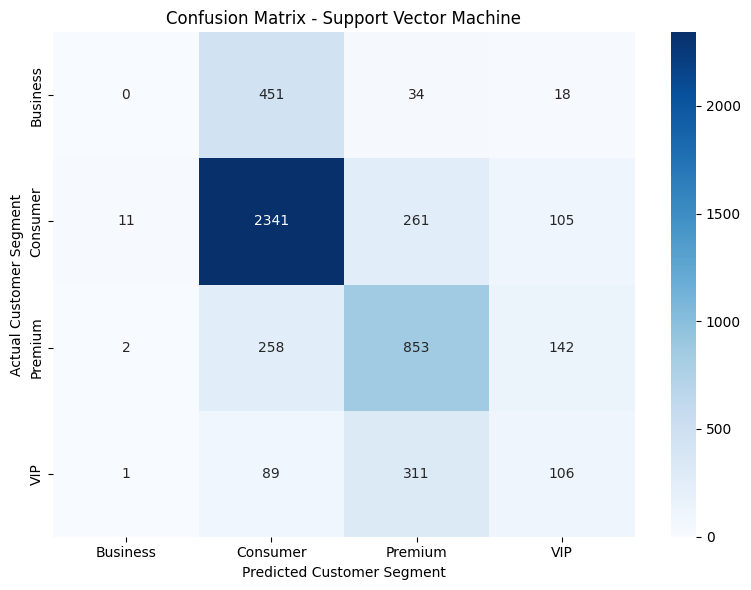

In [12]:
# ============================================================
# 15. CONFUSION MATRICES
# ============================================================

class_labels = sorted(y.unique())

for model_name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels
    )

    plt.title(
        "Confusion Matrix - " + model_name
    )

    plt.xlabel("Predicted Customer Segment")

    plt.ylabel("Actual Customer Segment")

    plt.tight_layout()

    plt.show()

In [13]:
# ============================================================
# 16. SAVE BEST MODEL
# ============================================================

best_model = trained_models[best_model_name]

joblib.dump(
    best_model,
    "best_ecommerce_customer_segment_model.pkl"
)

# Save comparison results
results_df.to_csv(
    "customer_segment_model_comparison.csv",
    index=False
)

# Save customer-level aggregated dataset
customer_data.to_csv(
    "ecommerce_customer_level_dataset.csv",
    index=False
)

print("Best Model:", best_model_name)

print("Model saved successfully!")

print("Comparison results saved successfully!")

print("Customer-level dataset saved successfully!")

Best Model: Support Vector Machine
Model saved successfully!
Comparison results saved successfully!
Customer-level dataset saved successfully!



TOP 20 IMPORTANT FEATURES


,Feature,Importance
27,shipping_cost_sum,0.133537
5,order_count,0.073492
62,customer_rating_sum,0.056489
7,quantity_sum,0.044130
47,profit_margin_percentage_sum,0.040441
57,estimated_delivery_days_sum,0.037259
22,tax_amount_sum,0.025678
63,customer_rating_mean,0.025051
82,order_month_sum,0.024182
30,shipping_cost_min,0.023171


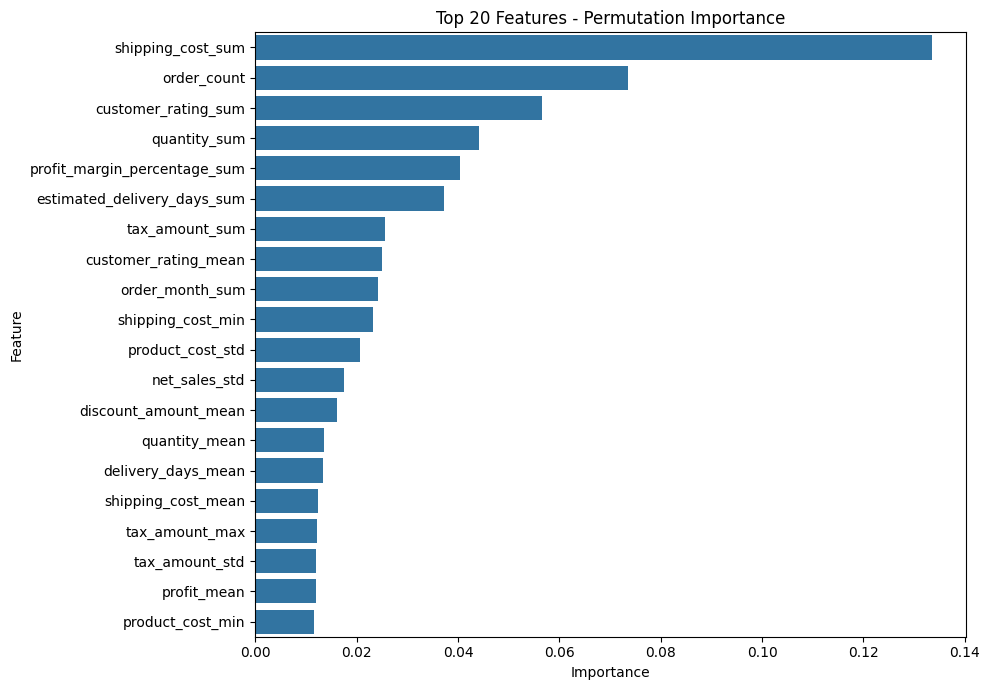

In [14]:
# ============================================================
# FEATURE IMPORTANCE USING PERMUTATION IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("\nTOP 20 IMPORTANT FEATURES")

display(importance_df.head(20))

# Plot
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(20),
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Features - Permutation Importance")

plt.tight_layout()

plt.show()